# Video analysis

This notebook is a template for analyzing a video of colloidal spheres with
pylorenzmie. Each frame is normalized by the background illumination, analyzed
with a **Frame**, and the results are collected in a **Trajectory**. Finally,
the measurements of the same particle in successive frames are linked together.

So that the notebook is self-contained, it first *simulates* a short video of two
spheres drifting through the field of view. To analyze your own video, replace
the simulated frames with your frames, as shown near the end.

In [1]:
%matplotlib inline
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trackpy as tp

from pylorenzmie.analysis import Frame, Trajectory
from pylorenzmie.theory import Cluster, Instrument, LorenzMie, Sphere
from pylorenzmie.utilities import Normalizer, VMedian

tp.quiet()
plt.rcParams['figure.dpi'] = 72

## A simulated video

The camera records raw counts (8-bit integers), not normalized intensities. The
illumination is brighter in the middle of the field of view, the camera adds a dark
count of 13, and there is noise. Two spheres, with different radii and refractive
indices, drift in opposite directions. We know exactly where they are in every
frame, so we can check the analysis. The $z_p$ coordinate is the distance of
a sphere from the focal plane, in pixels.

In [2]:
shape = (360, 480)                     # (rows, columns)
nframes = 20
dark_count = 13
noise = 0.03                           # camera noise, as a fraction of the signal

instrument = Instrument(wavelength=0.447, magnification=0.048, n_m=1.34,
                        noise=noise)
model = LorenzMie(instrument=instrument)
model.coordinates = model.meshgrid(shape)

rng = np.random.default_rng(3)
y, x = np.mgrid[:shape[0], :shape[1]]
illumination = 110. * (0.75 + 0.25 * np.exp(-((x - 220.)**2 + (y - 160.)**2)
                                            / (2 * 160.**2)))


def spheres(frame):
    '''The true properties of the spheres in a frame.'''
    return [dict(a_p=0.80, n_p=1.45, x_p=90 + 5.*frame, y_p=90 + 1.*frame,
                 z_p=130 + 1.5*frame),
            dict(a_p=0.95, n_p=1.58, x_p=400 - 4.*frame, y_p=270 - 1.*frame,
                 z_p=160 - 1.*frame)]


def record(spheres=None):
    '''The raw frame that the camera records.'''
    hologram = np.ones(shape)
    if spheres:
        # sphere positions are relative to the cluster, which we put at the origin
        model.particle = Cluster(particles=[Sphere(**s) for s in spheres],
                                 x_p=0., y_p=0., z_p=0.)
        hologram = model.hologram().reshape(shape)
    image = illumination * hologram + rng.normal(0., noise * illumination)
    return np.clip(image + dark_count, 0, 255).astype(np.uint8)


frames = [record(spheres(n)) for n in range(nframes)]
print(len(frames), 'frames of', frames[0].shape, frames[0].dtype)

20 frames of (360, 480) uint8


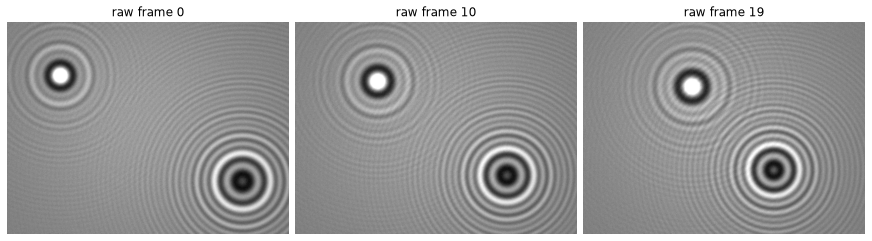

In [3]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 3.2), constrained_layout=True)
for ax, n in zip(axes, (0, 10, 19)):
    ax.imshow(frames[n], cmap='gray', vmin=0, vmax=200)
    ax.set_title(f'raw frame {n}')
    ax.axis('off')
plt.show()

## Normalizing with a background

The Lorenz-Mie analysis needs normalized holograms, with a background of 1.
The best background is a video of the same field of view without the particles.
Here we have nine such frames recorded before the spheres entered. A
**VMedian** computes a running median of a stream of frames, which suppresses
noise and any particle that moves through. (Used on frames that contain particles that
keep moving, it estimates the background without a separate recording.) A
**Normalizer** then divides each frame by the background after the dark count
is subtracted.

mean of a normalized frame: 0.999


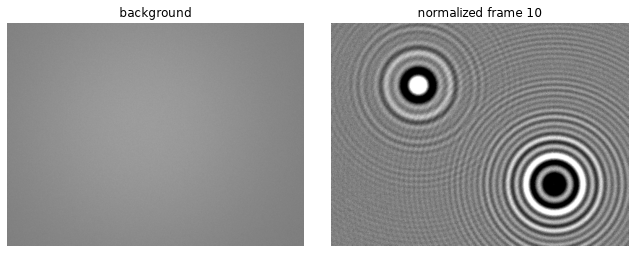

In [4]:
vmedian = VMedian(order=1)             # a median of 3**2 = 9 frames
for _ in range(9):
    vmedian.add(record())

background = vmedian.get().astype(float) - dark_count
normalizer = Normalizer(method='reference', reference=background)

norm = normalizer(frames[10].astype(float) - dark_count)
print('mean of a normalized frame:', norm.mean().round(3))

fig, axes = plt.subplots(ncols=2, figsize=(9, 3.4), constrained_layout=True)
axes[0].imshow(vmedian.get(), cmap='gray', vmin=0, vmax=200)
axes[0].set_title('background')
axes[1].imshow(norm, cmap='gray', vmin=0.5, vmax=1.5)
axes[1].set_title('normalized frame 10')
for ax in axes:
    ax.axis('off')
plt.show()

## Analyzing the frames

We analyze each frame with a **Frame**, with the instrument and a localizer
tuned to this kind of image. We know the kind of sample, so we tell each
feature's estimator where to search, and use a robust loss, as in the
*Fitting a single frame* tutorial. The results of each frame go into a
**Trajectory**, tagged with the frame number.

In [5]:
frame = Frame(instrument=instrument)
frame.localizer.diameter = 41
bounds = {'z_p': (60., 300.), 'a_p': (0.5, 2.), 'n_p': (1.3, 1.8)}

trajectory = Trajectory()
for number, raw in enumerate(frames):
    frame.data = normalizer(raw.astype(float) - dark_count)
    frame.detect()
    for feature in frame.features:
        feature.estimator.seed = 0
        feature.estimator.bounds = bounds
        feature.optimizer.robust = True
    frame.estimate()
    trajectory.append(frame.optimize().assign(frame=number))

data = trajectory.data
print(len(data), 'measurements in', nframes, 'frames')
data[['frame', 'x_p', 'y_p', 'z_p', 'a_p', 'n_p', 'redchi']].head(6)

40 measurements in 20 frames


,frame,x_p,y_p,z_p,a_p,n_p,redchi
0,0,90.021493,90.001219,129.971105,0.798925,1.450168,0.675686
1,0,399.995660,269.992670,159.998348,0.949681,1.580096,0.614891
2,1,95.030926,90.963815,131.550343,0.802117,1.449891,0.677617
3,1,395.990392,269.012268,159.073062,0.951269,1.579867,0.619295
4,2,99.966692,92.038172,133.290065,0.801327,1.450352,0.720398
5,2,392.023095,268.004550,152.227929,1.035250,1.787390,0.958041


## Linking the measurements

The trajectory holds measurements, not particles: nothing says which of the two
rows in a frame belongs to which sphere. **trackpy** links the positions in
successive frames into trajectories of particles, by finding the closest
match within a `search_range` (in pixels).

In [6]:
linked = tp.link(data, search_range=40, pos_columns=['x_p', 'y_p'],
                 t_column='frame')

summary = linked.groupby('particle')[['a_p', 'n_p']].median()
summary['frames'] = linked.groupby('particle').size()
summary

,a_p,n_p,frames
particle,,,
0,0.799297,1.450148,20
1,0.949984,1.580122,20


Each particle's radius and refractive index should not change from frame to
frame. They are fitted independently in every frame, so their spread is a
measure of the precision of the method, and an outlier is a frame where the fit went
wrong: a few frames of the second particle settled on a different minimum, with
a refractive index at the edge of the search range. The medians in the table above
are not affected. The true values are 0.80 µm and 1.45 for the first sphere, and
0.95 µm and 1.58 for the second, and the measured positions follow the true paths
(dashed).

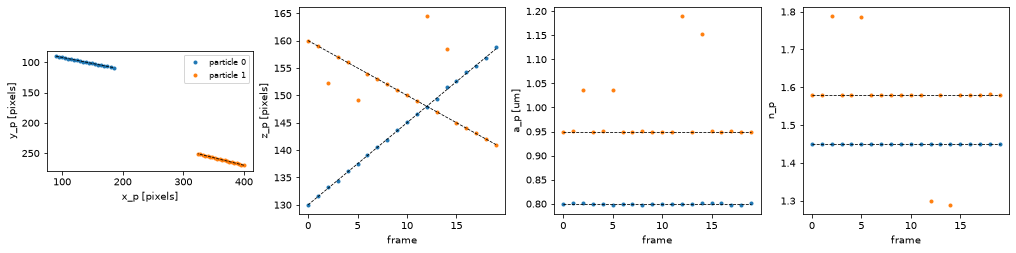

In [7]:
truth = pd.DataFrame([dict(frame=n, particle=i, **s)
                      for n in range(nframes)
                      for i, s in enumerate(spheres(n))])

fig, axes = plt.subplots(ncols=4, figsize=(14, 3.4), constrained_layout=True)
for number, group in linked.groupby('particle'):
    own = truth[truth.particle == (0 if group.x_p.iloc[0] < 240 else 1)]
    axes[0].plot(group.x_p, group.y_p, 'o', ms=3, label=f'particle {number}')
    axes[1].plot(group.frame, group.z_p, 'o', ms=3)
    axes[2].plot(group.frame, group.a_p, 'o', ms=3)
    axes[3].plot(group.frame, group.n_p, 'o', ms=3)
    axes[0].plot(own.x_p, own.y_p, 'k--', lw=0.8)
    axes[1].plot(own.frame, own.z_p, 'k--', lw=0.8)
    axes[2].plot(own.frame, own.a_p, 'k--', lw=0.8)
    axes[3].plot(own.frame, own.n_p, 'k--', lw=0.8)
axes[0].set(xlabel='x_p [pixels]', ylabel='y_p [pixels]', aspect='equal')
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)
axes[1].set(xlabel='frame', ylabel='z_p [pixels]')
axes[2].set(xlabel='frame', ylabel='a_p [um]')
axes[3].set(xlabel='frame', ylabel='n_p')
plt.show()

## Analyzing your own video

Replace the simulated frames with frames from your video. With OpenCV, read
them one at a time and convert to a single channel:

```python
import cv2

video = cv2.VideoCapture('video.avi')
frames = []
while True:
    ok, image = video.read()
    if not ok:
        break
    frames.append(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY))
```

Build the background from a recording without particles, or from a **VMedian** that
runs through the video frames themselves, set the `dark_count` of your camera
and the `instrument` of your microscope, and the loop above does the rest. The
results of a long video can be written to a file with `trajectory.to_csv()`.